# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`data/plans.csv`**  
  - **`data/users_latam.csv`**  
  - **`data/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('data/plans.csv')
users = pd.read_csv('data/users_latam.csv')
usage = pd.read_csv('data/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 260.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean()*100)
print(users[users['churn_date'].isna()])

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64
      user_id first_name last_name  age      city  \
0       10000     Carlos    Garcia   38  Medellín   
1       10001      Mateo    Torres   53         ?   
2       10002      Sofia   Ramirez   57      CDMX   
3       10003      Mateo   Ramirez   69    Bogotá   
4       10004      Mateo    Torres   63       GDL   
...       ...        ...       ...  ...       ...   
3995    13995        Ana     Lopez   60  Medellín   
3996    13996     Carlos   Ramirez   24  Medellín   
3997    13997        Ana     Lopez   58    Bogotá   
3998    13998    Mariana     Lopez   57    Bogotá   
3999    13999        Ana     Lopez   20    Bogotá   

               

In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean()*100)
print(usage[usage['duration'].isna()])
print(usage[usage['length'].isna()])

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64
          id  user_id  type                           date  duration  length
1          2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2          3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
8          9    11530  text  2024-01-01 00:52:07.758193954       NaN    44.0
9         10    12850  text  2024-01-01 00:58:38.727968199       NaN    70.0
11        12    10824  text  2024-01-01 01:11:40.667516687       NaN    31.0
...      ...      ...   ...                            ...       ...     ...
39979  39980    13582  text  2024-06-29 21:49:40.604515112       NaN    41.0
39981  39982    11256  text  2024-06-29 22:02:42.544063600       NaN    48.0
39985  39986    11966  text  2024-06-29 22:28:46.42316057

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?

las columnas que tienen valores faltantes son city con 11,7%, churn_date con 88,3%, duration con 55%, length con 44% y date con 0.1%

- Indica qué harías: ¿imputar, eliminar, ignorar?

Con la columna churn_date ignoraria los valores nulos debido al tipo de dato, esto a la razón de que los valores nulos representan que no hubo fecha de perdida de clientes.

Con la columna duration imputaria los valores con NaN filtrando por tipo de servicio es decir filtrar por texto e imputar con 0 los valores ausentes de duration ya que un mensaje de texto no tiene duración.

La misma lógica se aplica para la columna length filtrando por llamada, imputar con 0 los valores ausentes en la columna length ya que una llamada no tiene longitud de caracteres.

La columna city la podemos dejar como nulos, ya que no se puede reemplazar la ciudad o inventar el valor en esa columna porque se estaria sesgando la información.

La columna date los dejaré como nulos debido a que no se pueden imputar fechas.


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [13]:
users.isin([-999,'NA','?']).sum()

,0
user_id,0
first_name,0
last_name,0
age,55
city,96
reg_date,0
plan,0
churn_date,0


- La columna `user_id` es una columna de identificación de usuario, no es una variable relevante como metrica. No se observan valores invalidos ni sentinels.
- La columna `age` se observa sentinel en el minimo de la distribucion estadistica, distorsionando el promedio.

In [14]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


In [15]:
usage.isin([-999,'NA','?']).sum()

,0
id,0
user_id,0
type,0
date,0
duration,0
length,0


- Las columnas `id` y `user_id`son columnas de identificacion en relación a los registros que estan en el dataset y dichos registros asociados los usuarios de los servicios telefonicos.
- Las columnas duration se observa inicialmente que la mediana y media no coinciden entre si, no se observan sentinels en el resumen. Del mismo modo la columna length se observa que la mediana y media estan relativamente cercanas entre si, no se aprecian valores invalidos. En ambas columnas se observan inicialmente valores atipicos altos en los maximos.

In [16]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].describe())
print()
print(users[columnas_user].value_counts())
users[columnas_user].isin([-999,'NA','?',' ']).sum()

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595

city      plan   
Bogotá    Basico     522
CDMX      Basico     474
Medellín  Basico     398
GDL       Basico     298
Bogotá    Premium    286
MTY       Basico     275
Cali      Basico     262
CDMX      Premium    256
Medellín  Premium    218
Cali      Premium    162
GDL       Premium    152
MTY       Premium    132
?         Basico      65
          Premium     31
Name: count, dtype: int64


,0
city,96
plan,0


In [17]:
valores_validos = ['Bogotá','CDMX','Medellín','GDL','MTY','Cali']
raros = users.loc[~users['city'].isin(valores_validos), 'city']
print(raros.apply(repr).unique())

["'?'" 'nan']


- La columna `city` se observa inicialmente 3531 registros de 4000, 7 valores unicos, su moda es la ciudad de Bogotá, y su frecuencia en los registros es de 808 veces. Se observan 96 sentinels distribuidos en `?` con la categoria Basico y cantidad de 65 registros y en formato `nan` con la categoria Premium y cantidad de 31 registros..
- La columna `plan` se observa preliminarmente sus 4000 registros, 2 valores unicos, su moda siendo Basico y su frecuencia de 2595 veces. No se observan sentinels.

In [18]:
# explorar columna categórica de usage
print(usage['type'].describe())
usage.isin([-999,'NA','?']).sum()

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object


,0
id,0
user_id,0
type,0
date,0
duration,0
length,0


- La columna `type` se observa inicialmente los 40000 registros, sus 2 valores unicos, la moda siento el servicio texto y su frecuencia con 22092 registros. No se observan sentinels.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?

  En la columnas city se encontraron valores inválidos en formato `?` y sentinels en la columna age en formato `-999`
- ¿Qué acción tomarías?

  En la columna city se debe reemplazar los valores inválidos `?` por NaNs, esto debido a que los 31 registros en blanco que se observan en la detección de invalidos `nan` no necesitan transformacion porque ya son considerados nulos. Los sentinels de la columna age `-999` primero se debe reemplazar por NaNs y luego imputar por la media.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [19]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors = 'coerce', utc = True)

In [20]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors = 'coerce', utc = True)

In [21]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024], dtype=int32)

En `reg_date`, los usuarion se registraron en el año 2022, 2023 y 2024. Se detecta un año fuera de rango correspondiente al 2026.

In [22]:
users[users['reg_date'].dt.year == 2026].shape[0]

40

In [23]:
users[users['reg_date'].dt.year < 2022].shape[0]

0

In [24]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()

array([2024.,   nan])

En `date`, el año presente es unicamente el año 2024 con fechas ausentes.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)

  Aparece el año 2026 como imposible o sin transcurrir al momento de guardar los datos
  
- ¿Qué harías con ellas?

  Reemplazar esas fechas fuera de rango como NA y eliminarlas, esto debido a que no se puede inventar una fecha para reemplazar esos valores fuera de rango y tambien como valores nulos no aportan información relevante al análisis de antiguedad y permanencia del cliente cuando se registró.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [25]:
#verificación de sentinel antes de imputación
(users['age'] == -999).sum()

np.int64(55)

In [26]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999,age_mediana)

# Verificar cambios
users['age'].describe()

,age
count,4000.000000
mean,48.122250
std,17.690408
min,18.000000
25%,33.000000
50%,47.000000
75%,63.000000
max,79.000000


In [27]:
#verificación de sentinel antes de imputación
(users['city'] == '?').sum()

np.int64(96)

In [28]:
# Reemplazar ? por NA en city

users['city'] = users['city'].replace('?', pd.NA)
# Verificar cambios
users['city'].describe()

,city
count,3435
unique,6
top,Bogotá
freq,808


In [29]:
(users['city'].isin(['NA','nan'])).sum()

np.int64(0)

In [30]:
pd.Timestamp(2024, tz='UTC')

Timestamp('1970-01-01 00:00:00.000002024+0000', tz='UTC')

In [31]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'] > pd.Timestamp('2024-12-31', tz = 'UTC'), 'reg_date'] = pd.NA

# Verificar cambios
users['reg_date'].dt.year.unique()

array([2022.,   nan, 2023., 2024.])

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [32]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).sum()

,duration
type,
call,0
text,22076


In [33]:
columnas_filtrado = ['type','duration']
usage.loc[(usage['type'] == 'text') & (usage['duration'].notna()), columnas_filtrado]

,type,duration
1414,text,120.0
1824,text,120.0
1932,text,120.0
2972,text,120.0
11456,text,120.0
16702,text,120.0
22814,text,120.0
23052,text,120.0
23451,text,120.0
26561,text,120.0


In [34]:
 usage.loc[(usage['type'] == 'call') & (usage['duration'] == 120)]

,id,user_id,type,date,duration,length
2832,2833,13953,call,2024-01-13 19:33:46.400660016+00:00,120.0,NaN
2894,2895,11589,call,2024-01-14 02:17:46.526663166+00:00,120.0,NaN
3986,3987,13493,call,2024-01-19 00:53:25.520138003+00:00,120.0,NaN
8265,8266,11727,call,2024-02-07 09:36:05.184129603+00:00,120.0,NaN
12921,12922,13945,call,2024-02-28 11:15:20.453011325+00:00,120.0,NaN
13235,13236,10349,call,2024-02-29 21:21:24.962124053+00:00,120.0,NaN
14128,14129,13187,call,2024-03-04 22:20:20.970524263+00:00,120.0,NaN
15517,15518,11304,call,2024-03-11 05:11:17.986949673+00:00,120.0,NaN
19360,19361,10216,call,2024-03-28 14:32:54.829370734+00:00,120.0,NaN
20237,20238,10226,call,2024-04-01 13:47:35.321383034+00:00,120.0,NaN


In [35]:
# Se imputa valores sentinels de text por NaN
usage.loc[(usage['type'] == 'text') & (usage['duration'] == 120), 'duration'] = np.nan

In [36]:
#Verificación de cambios
columnas_filtrado = ['type','duration']
usage.loc[(usage['type'] == 'text') & (usage['duration'] == 120), columnas_filtrado]

,type,duration


In [37]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).sum()

,length
type,
call,17896
text,0


In [38]:
columnas_filtrado = ['type','length']
usage.loc[(usage['type'] == 'call') & (usage['length'].notna()), columnas_filtrado]

,type,length
2070,call,1490.0
5272,call,1490.0
10614,call,1490.0
12692,call,1490.0
16910,call,1490.0
20727,call,1490.0
20778,call,1490.0
25444,call,1490.0
26057,call,1490.0
26506,call,1490.0


In [39]:
 usage.loc[(usage['type'] == 'text') & (usage['length'] == 1490)]

,id,user_id,type,date,duration,length
992,993,10869,text,2024-01-05 11:44:02.016050401+00:00,NaN,1490.0
3038,3039,10381,text,2024-01-14 17:56:06.174154353+00:00,NaN,1490.0
7786,7787,13483,text,2024-02-05 05:34:50.662266556+00:00,NaN,1490.0
13408,13409,11458,text,2024-03-01 16:08:42.733068326+00:00,NaN,1490.0
13416,13417,10071,text,2024-03-01 17:00:50.491262281+00:00,NaN,1490.0
14415,14416,11931,text,2024-03-06 05:30:29.295732393+00:00,NaN,1490.0
15153,15154,12439,text,2024-03-09 13:39:24.989124728+00:00,NaN,1490.0
17258,17259,12673,text,2024-03-19 02:15:56.363909097+00:00,NaN,1490.0
21357,21358,12657,text,2024-04-06 15:25:41.468536713+00:00,NaN,1490.0
22806,22807,11111,text,2024-04-13 04:47:36.671416785+00:00,NaN,1490.0


In [40]:
# Se imputa valores sentinels de call por NaN
usage.loc[(usage['type'] == 'call') & (usage['length'] == 1490), 'length'] = np.nan

In [41]:
columnas_filtrado = ['type','length']
usage.loc[(usage['type'] == 'call') & (usage['length'] == 1490), columnas_filtrado]

,type,length


Las nulos observados en las columnas duration y length son considerados MAR (missing at random) debido a que estan relacionado a la columna type, estos se logra corroborar al identificar los nulos tanto para mensajes como para llamadas. En el caso de duration se identifica la cantidad de NaN en 22076 registros correspondientes al tipo de servicio texto, explicando que no hay duracion en este servicio. De la misma manera en el servicio de llamadas se observan nulos en 17896 registros, indicando que es natural que hayan nulos por la naturaleza del servicio, en este caso no puede haber longitud de caracteres en el servicio de llamadas. Por otro lado, se decide investigar ciertos registros que aun siendo llamadas o texto no estan presentes en su respectiva categoria, es decir, se observan registros por ejemplo siendo llamadas tienen longitud de caracteres y lo mismo para los de tipo texto. Por lo tanto al observar dichos registros se observa un patron numerico que se considera como sentinels. Estos, se evaluan como datos por defectos que el mismo sistema designo al no categorizarlos en su debido proceso. Finalmente se decide imputar por NaNs estos sentinels para dejar más consistente el data set de type con su categoria texto y llamada.

---


## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.


In [42]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario usando una lista de columnas
usage_agg = usage.groupby('user_id')[['is_text', 'is_call', 'duration']].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [43]:

# Renombrar columnas
usage_agg = usage_agg.rename( columns = {'is_text': 'cant_mensajes','is_call':'cant_llamadas','duration':'cant_minutos_llamada'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [44]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on='user_id', how = 'left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [45]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.122250,5.524381,4.478120,22.836934
std,1154.844867,17.690408,2.358416,2.144238,16.590213
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.095000
50%,11999.500000,47.000000,5.000000,4.000000,19.740000
75%,12999.250000,63.000000,7.000000,6.000000,31.185000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [46]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize = True)*100

,proportion
plan,
Basico,64.875
Premium,35.125


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

In [47]:
user_profile.groupby('plan')['age'].describe()

,count,mean,std,min,25%,50%,75%,max
plan,,,,,,,,
Basico,2595.0,48.025819,17.537967,18.0,33.0,47.0,63.0,79.0
Premium,1405.0,48.300356,17.973494,18.0,33.0,48.0,64.0,79.0


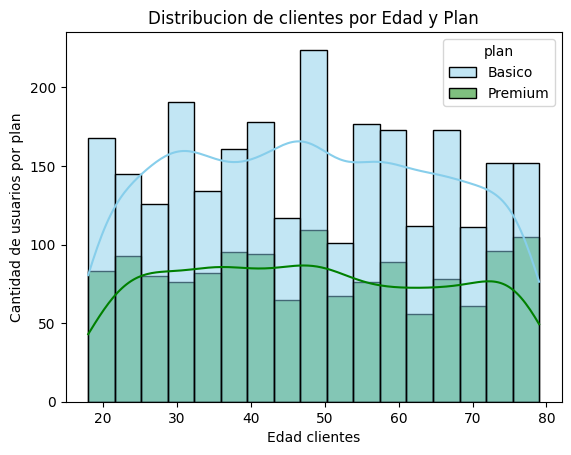

In [48]:
# Histograma para visualizar la edad (age)
sns.histplot(data = user_profile,  x = 'age', hue = 'plan', palette = ['skyblue', 'green'], kde = True)
plt.xlabel('Edad clientes')
plt.ylabel('Cantidad de usuarios por plan')
plt.title('Distribucion de clientes por Edad y Plan')
plt.show()

In [49]:
user_profile[user_profile['age'] == 47]['plan'].value_counts()

,count
plan,
Basico,82
Premium,33


In [50]:
user_profile[user_profile['age'].between(47,50)]['plan'].value_counts()

,count
plan,
Basico,224
Premium,109


In [51]:
user_profile[user_profile['age'].between(47,50)]['plan'].value_counts(normalize = True) * 100

,proportion
plan,
Basico,67.267267
Premium,32.732733


💡Insights:
-  Se observa inicialmente una distribución aproximadamente simétrica con un pico de concentración de clientes entre los 47 y 50 años. Dentro de este rango se distingue que la proporcion entre el rango de 47 y 50 años es similar a la base de clientes general de la empresa, es decir no hay una mayor proporción en cantidad de usuarios entre el plan básico y premium en relación a la variable edad.

In [52]:
user_profile.groupby('plan')['cant_mensajes'].describe()

,count,mean,std,min,25%,50%,75%,max
plan,,,,,,,,
Basico,2594.0,5.527756,2.36282,0.0,4.0,5.0,7.0,17.0
Premium,1405.0,5.518149,2.35109,0.0,4.0,5.0,7.0,16.0


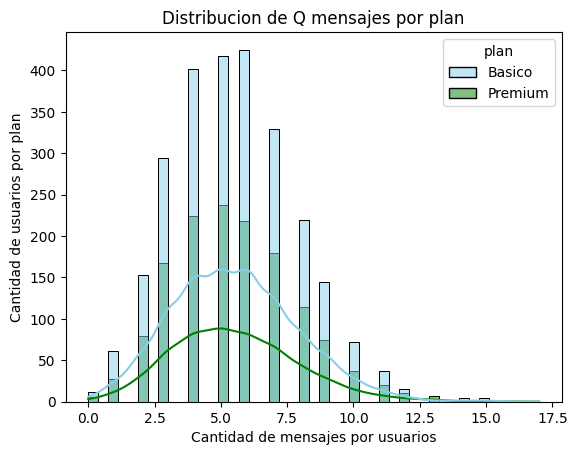

In [53]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data= user_profile, x = 'cant_mensajes', hue = 'plan', palette = ['skyblue','green'], kde = True)
plt.xlabel('Cantidad de mensajes por usuarios')
plt.ylabel('Cantidad de usuarios por plan')
plt.title('Distribucion de Q mensajes por plan')
plt.show()

In [54]:
user_profile[user_profile['cant_mensajes'].between(4,7)]['plan'].value_counts()

,count
plan,
Basico,1573
Premium,860


In [55]:
user_profile[user_profile['cant_mensajes'].between(4,7)]['plan'].value_counts(normalize = True)*100

,proportion
plan,
Basico,64.652692
Premium,35.347308


💡Insights:
- Se observa preliminarmente una distribución mayormente simétrica con una concentracion de datos entre los valores de 4 y 7 de cantidad de mensajes por usuarios, los valores como el Q1, media, mediana y Q3 se encuentran cercanos entre sí dentro del rango mencionado. Por otro lado se observa un leve sesgo hacia la derecha que arrastra la distribución como límite máximo del rango de datos. Adicionalmente se detecta que las proporciones de cantidad de usuarios por plan que envian entre 4 a 7 mensajes se componen de manera similar a la proporción, 64% pertenecen al plan básico y 35% pertenecen al plan premium, de la distribución de la base general de clientes por plan de la empresa.

In [56]:
user_profile.groupby('plan')['cant_llamadas'].describe()

,count,mean,std,min,25%,50%,75%,max
plan,,,,,,,,
Basico,2594.0,4.456438,2.168347,0.0,3.0,4.0,6.0,15.0
Premium,1405.0,4.518149,2.099177,0.0,3.0,4.0,6.0,11.0


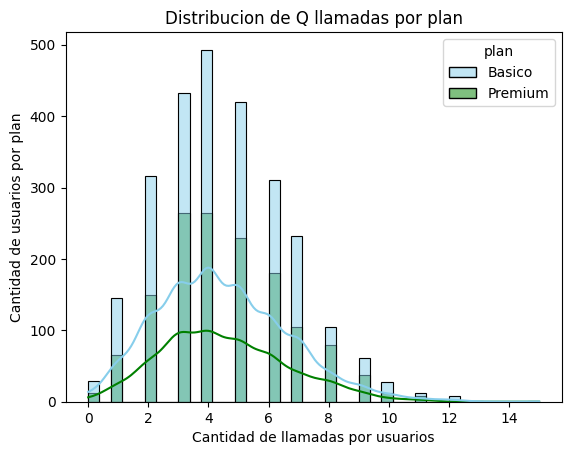

In [57]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data= user_profile, x = 'cant_llamadas', hue = 'plan', palette = ['skyblue','green'], kde = True)
plt.xlabel('Cantidad de llamadas por usuarios')
plt.ylabel('Cantidad de usuarios por plan')
plt.title('Distribucion de Q llamadas por plan')
plt.show()

In [58]:
user_profile[user_profile['cant_llamadas'].between(3,6)]['plan'].value_counts()

,count
plan,
Basico,1656
Premium,937


In [59]:
user_profile[user_profile['cant_llamadas'].between(3,6)]['plan'].value_counts(normalize = True)*100

,proportion
plan,
Basico,63.86425
Premium,36.13575


💡Insights:
- Distribución aproximadamente simétrica con un leve sesgo hacia la derecha debido al valor atipico que se presenta en el rango superior de los datos que jala la distribución. La concentración de datos se encuentran en los rangos de valores 3 y 6, esto también se representa con los valores estadisticos del Q1, media, mediana y Q3 cercanos entre si dentro del rango mencionado. De la misma manera las proporciones de cantidad de usuarios que tienen una cantidad de llamadas entre 3 a 6 se conforman entre un 63% y 36% de los planes básico y premium, respectivamente, siendo su composición similar a la base general de clientes de la empresa.

In [60]:
user_profile.groupby('plan')['cant_minutos_llamada'].describe()

,count,mean,std,min,25%,50%,75%,max
plan,,,,,,,,
Basico,2594.0,22.581611,16.527352,0.0,10.895,19.52,30.5925,155.69
Premium,1405.0,23.308327,16.701293,0.0,11.580,20.30,32.1900,153.06


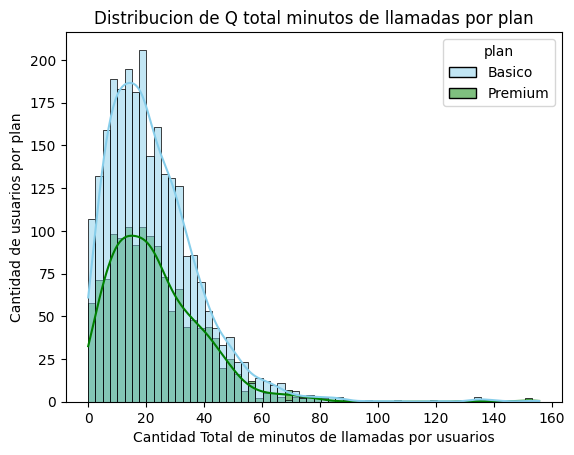

In [61]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data= user_profile, x = 'cant_minutos_llamada', hue = 'plan', palette = ['skyblue','green'], kde = True)
plt.xlabel('Cantidad Total de minutos de llamadas por usuarios')
plt.ylabel('Cantidad de usuarios por plan')
plt.title('Distribucion de Q total minutos de llamadas por plan')
plt.show()

In [62]:
user_profile[user_profile['cant_minutos_llamada'].between(10,32)]['plan'].value_counts()

,count
plan,
Basico,1425
Premium,752


In [63]:
user_profile[user_profile['cant_minutos_llamada'].between(10,32)]['plan'].value_counts(normalize = True)*100

,proportion
plan,
Basico,65.457051
Premium,34.542949


💡Insights:
- Distribución sesgada hacia la derecha debido a los valores máximos que jalan la distribución. La concentracion de datos se encuentra en los rangos de los 10 y 32 minutos de llamadas por usuarios representados por los cuartiles Q1, media, mediana y Q3 en el estadistico. Las proporciones entre la cantidad de usuarios que realizan llamadas entre 10 a 32 minutos es de un 65% y 34% de los planes básico y premium, respectivamente, similar a la base de clientes generales de la empresa por plan.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

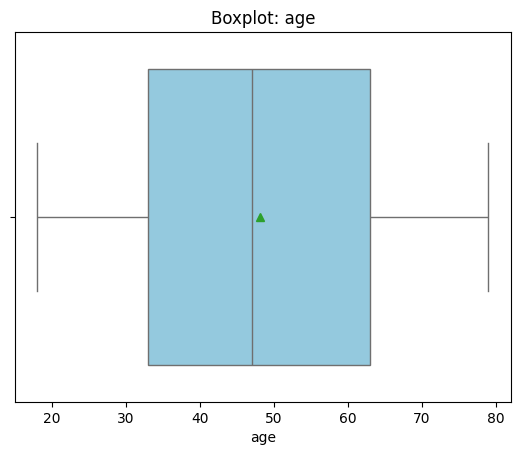

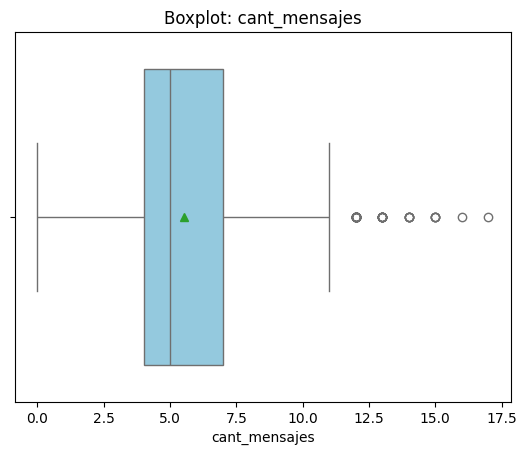

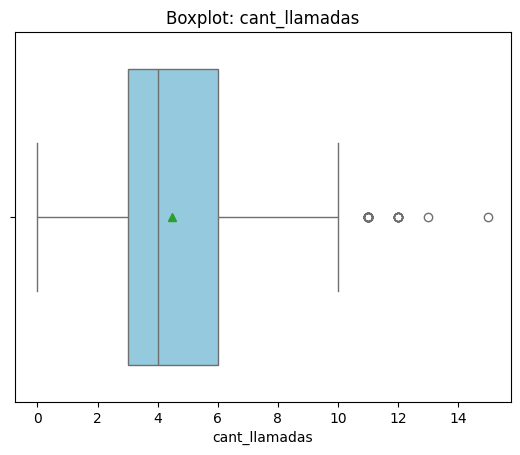

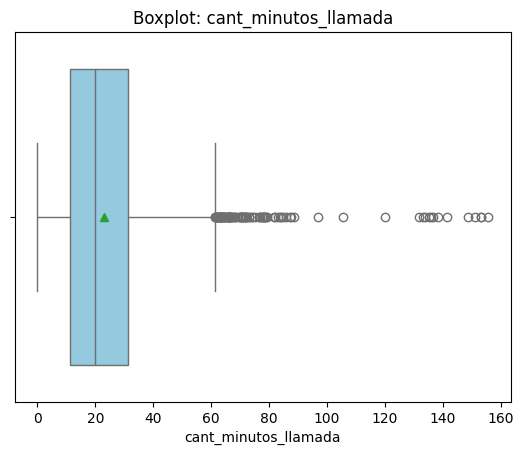

In [64]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot( x = user_profile[col], color = 'skyblue', showmeans = True)
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:
- Age: No presenta outliers, tiene una distribución controlada.
- cant_mensajes: Presenta outliers
- cant_llamadas: Presenta outliers
- cant_minutos_llamada: Presenta outliers extremos.

Primer cuartil cant_mensajes: 4.0
Tercer cuartil cant_mensajes: 7.0
IQR cant_mensajes: 3.0
Límite superior cant_mensajes: 11.5
Cantidad outlier cant_mensajes: 46


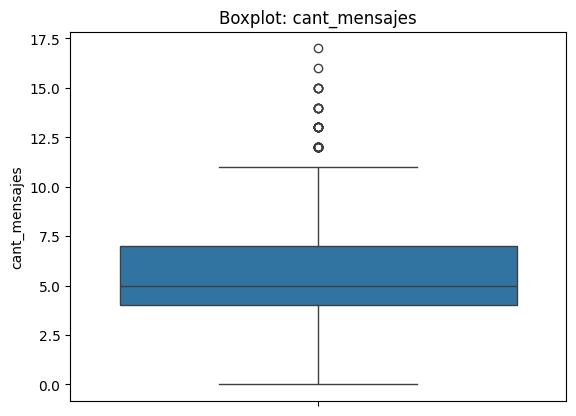

Primer cuartil cant_llamadas: 3.0
Tercer cuartil cant_llamadas: 6.0
IQR cant_llamadas: 3.0
Límite superior cant_llamadas: 10.5
Cantidad outlier cant_llamadas: 30


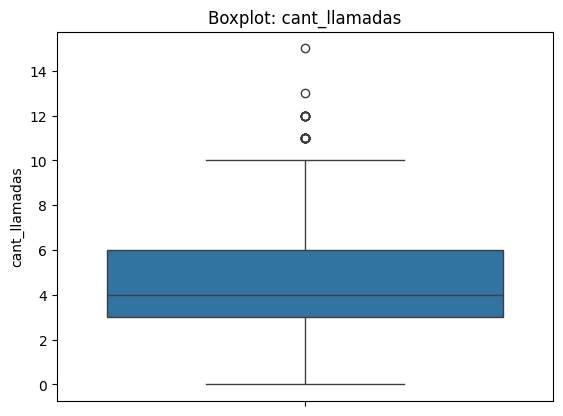

Primer cuartil cant_minutos_llamada: 11.094999999999999
Tercer cuartil cant_minutos_llamada: 31.185
IQR cant_minutos_llamada: 20.09
Límite superior cant_minutos_llamada: 61.31999999999999
Cantidad outlier cant_minutos_llamada: 96


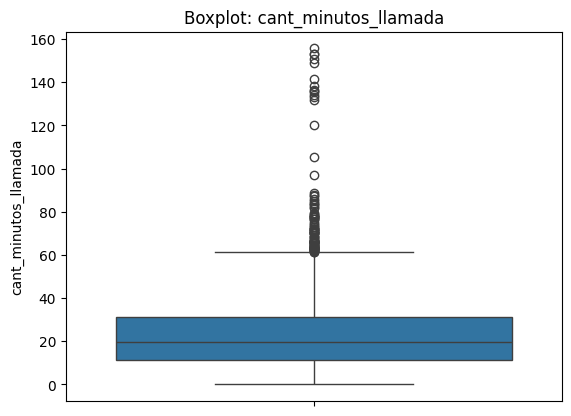

In [65]:
# Calcular límites con el método IQR
limites_superiores = []
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    print(f'Primer cuartil {col}:', Q1)
    Q3 = user_profile[col].quantile(0.75)
    print(f'Tercer cuartil {col}:', Q3)
    IQR = Q3 - Q1
    print(f'IQR {col}:', IQR)
    limite_superior = Q3 + 1.5 * IQR
    print(f'Límite superior {col}:', limite_superior)
    limites_superiores.append(limite_superior)
    cantidad_outliers = user_profile[user_profile[col] > limite_superior].shape[0]
    print(f'Cantidad outlier {col}:', cantidad_outliers)
    sns.boxplot(data=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.ylabel(col)
    plt.show()

In [66]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
describe_col_lim = user_profile[columnas_limites].describe()
describe_col_lim.loc['limite_superior'] = limites_superiores
describe_col_lim

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,22.836934
std,2.358416,2.144238,16.590213
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.095000
50%,5.000000,4.000000,19.740000
75%,7.000000,6.000000,31.185000
max,17.000000,15.000000,155.690000
limite_superior,11.500000,10.500000,61.320000


💡Insights:
- cant_mensajes: Se mantienen los outliers, esto porque el maximo de 17 mensajes no representa una variedad anormal de comportamiento de uso del usuario sino todo lo contrario, es un comportamiento normal de comunicación en lo que respecta en un periodo de un año.
- cant_llamadas: Se mantienen los outliers, debido a que el comportamiento de usuarios puede deberse a motivos laborales, power users o usuarios cuya necesidad social influyen en la frecuencia de cantidad de llamadas.
- cant_minutos_llamada: Se mantienen los outliers, las razones son por trabajo y familia, los dos están ligados ya que el trabajo remoto o a distancia demanda llamadas de gran duración en pocas cantidades y la familia también puede demandar ese comportamiento ya que si un trabajador esta alejado de su familia necesitara conversar con ellos en mayor medida por la lejanía del trabajo.




---


## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [67]:
# Crear columna grupo_uso
def seg_clientes_uso (row):
    mensajes = row['cant_mensajes']
    llamadas = row['cant_llamadas']

    if pd.isna(mensajes) or pd.isna(llamadas):
        return 'Error en datos'
    if llamadas < 5 and mensajes < 5:
        return 'Bajo uso'
    elif llamadas < 10 and mensajes < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'
user_profile['grupo_uso'] = user_profile.apply(seg_clientes_uso, axis = 1)

In [68]:
#Verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso


In [69]:
user_profile[(user_profile['cant_mensajes'] > 10) & (user_profile['cant_llamadas'] > 10)]

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
3819,13819,Luis,Torres,25,<NA>,2024-11-11 17:06:15.393848464+00:00,Premium,NaN,16.0,11.0,47.8,Alto uso


In [70]:
# Filtro de consumo de cantidad de minutos mayor a 100 minutos por usuarios - plan básico.
user_profile[(user_profile['cant_minutos_llamada'] > 100) & (user_profile['plan'] == 'Basico')].sort_values( by = 'cant_minutos_llamada',ascending = False)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
3953,13953,Mateo,Gomez,58,GDL,2024-12-18 09:42:15.933983504+00:00,Basico,NaN,0.0,7.0,155.69,Uso medio
349,10349,Ana,Gomez,67,GDL,2022-04-06 13:30:12.153038260+00:00,Basico,NaN,6.0,7.0,150.92,Uso medio
2472,12472,Carlos,Garcia,46,<NA>,2023-11-08 21:06:04.591147792+00:00,Basico,"1,71919E+18",6.0,7.0,141.37,Uso medio
3187,13187,Luis,Lopez,63,GDL,2024-05-22 15:49:33.443360848+00:00,Basico,"1,72981E+18",3.0,5.0,138.41,Uso medio
3927,13927,Mariana,Lopez,18,GDL,2024-12-11 06:50:30.157539392+00:00,Basico,"1,72549E+18",8.0,4.0,135.96,Uso medio
1304,11304,Luis,Ramirez,26,NaN,2022-12-24 01:25:20.480120032+00:00,Basico,NaN,9.0,7.0,135.36,Uso medio
3945,13945,Luis,Ramirez,30,Bogotá,2024-12-16 05:07:52.618154544+00:00,Basico,NaN,7.0,3.0,133.97,Uso medio
1727,11727,Mateo,Garcia,64,Bogotá,2023-04-18 21:13:38.304576144+00:00,Basico,NaN,7.0,5.0,133.10,Uso medio
226,10226,Luis,Torres,26,GDL,2022-03-03 21:11:28.672168042+00:00,Basico,NaN,1.0,1.0,120.00,Bajo uso
3612,13612,Sofia,Ramirez,22,Medellín,2024-09-16 00:46:27.096774192+00:00,Basico,NaN,5.0,9.0,105.54,Uso medio


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [71]:
# Crear columna grupo_edad
def seg_clientes_edad(row):
    edad = row['age']
    if pd.isna(edad):
        return 'Error en datos'
    if edad < 30:
        return 'Joven'
    elif edad < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'
user_profile['grupo_edad'] = user_profile.apply(seg_clientes_edad, axis = 1)

In [72]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

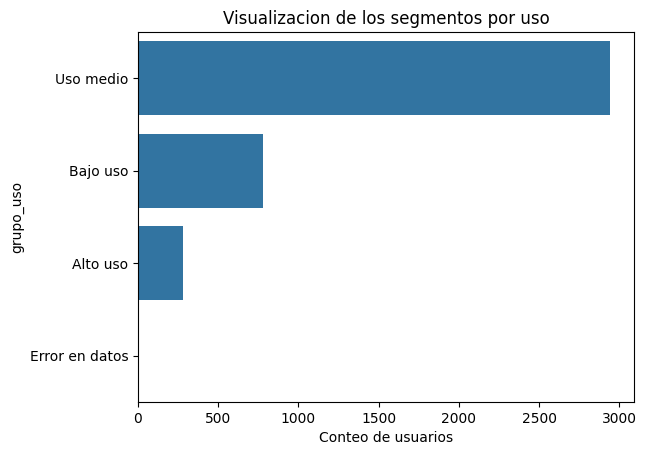

In [73]:
# Visualización de los segmentos por uso
sns.countplot(data = user_profile, y ='grupo_uso', order = user_profile['grupo_uso'].value_counts().index)
plt.title('Visualizacion de los segmentos por uso')
plt.xlabel('Conteo de usuarios')
plt.show()

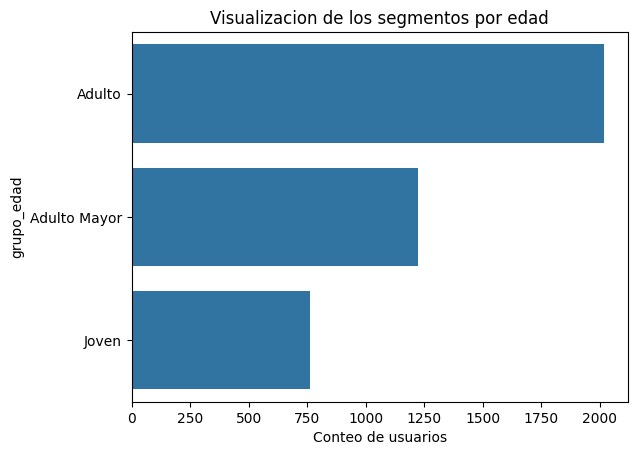

In [74]:
# Visualización de los segmentos por edad
sns.countplot(data = user_profile, y = 'grupo_edad', order = user_profile['grupo_edad'].value_counts().index)
plt.title('Visualizacion de los segmentos por edad')
plt.xlabel('Conteo de usuarios')
plt.show()

In [75]:
# Distribución porcentual por segmento de uso.
user_profile.groupby('grupo_uso')['plan'].value_counts(normalize = True) * 100

grupo_uso       plan   
Alto uso        Basico      66.546763
                Premium     33.453237
Bajo uso        Basico      65.809769
                Premium     34.190231
Error en datos  Basico     100.000000
Uso medio       Basico      64.458036
                Premium     35.541964
Name: proportion, dtype: float64

In [76]:
# Distribución relativa por segmento de uso.
user_profile.groupby('grupo_uso')['plan'].value_counts()

grupo_uso       plan   
Alto uso        Basico      185
                Premium      93
Bajo uso        Basico      512
                Premium     266
Error en datos  Basico        1
Uso medio       Basico     1897
                Premium    1046
Name: count, dtype: int64

In [77]:
# Distribución relativa por segmento de edad.
user_profile.groupby('grupo_edad')['plan'].value_counts()

grupo_edad    plan   
Adulto        Basico     1325
              Premium     693
Adulto Mayor  Basico      784
              Premium     438
Joven         Basico      486
              Premium     274
Name: count, dtype: int64

In [78]:
# Distribución porcentual por segmento de edad.
user_profile.groupby('grupo_edad')['plan'].value_counts(normalize =  True) * 100

grupo_edad    plan   
Adulto        Basico     65.659068
              Premium    34.340932
Adulto Mayor  Basico     64.157119
              Premium    35.842881
Joven         Basico     63.947368
              Premium    36.052632
Name: proportion, dtype: float64

In [79]:
planes = {'Basico' : 12, 'Premium' : 25}
user_profile['valor_planes'] = user_profile['plan'].map(planes)

In [80]:
#Valor de segmento por grupo uso en USD.
user_profile.groupby('grupo_uso')['valor_planes'].sum()

,valor_planes
grupo_uso,
Alto uso,4545
Bajo uso,12794
Error en datos,12
Uso medio,48914


In [81]:
#Valor de segmento por grupo edad en USD.
user_profile.groupby('grupo_edad')['valor_planes'].sum()

,valor_planes
grupo_edad,
Adulto,33225
Adulto Mayor,20358
Joven,12682


In [82]:
# Filtro por grupo uso medio y grupo edad adulto
user_profile[(user_profile['grupo_uso']=='Uso medio') & (user_profile['grupo_edad']=='Adulto')]['plan'].value_counts()

,count
plan,
Basico,977
Premium,523


In [83]:
#Estadísticas descriptivas para el segmento uso medio y edad adulto
user_profile[(user_profile['grupo_uso']=='Uso medio') & (user_profile['grupo_edad']=='Adulto')].describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada,valor_planes
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,11969.384000,44.294000,5.743333,4.746000,23.994407,16.532667
std,1157.213378,8.627467,1.839849,1.955514,15.539720,6.197193
min,10000.000000,30.000000,0.000000,0.000000,0.000000,12.000000
25%,10964.000000,37.000000,5.000000,3.000000,12.735000,12.000000
50%,11981.500000,44.000000,6.000000,5.000000,21.585000,12.000000
75%,12959.000000,51.000000,7.000000,6.000000,32.512500,25.000000
max,13998.000000,59.000000,9.000000,9.000000,155.690000,25.000000


In [84]:
#Filtrado de usuarios de alto consumo desde limite del plan básico (100 minutos)  - distribución relativa
user_profile[(user_profile['grupo_uso']=='Uso medio') & (user_profile['grupo_edad']=='Adulto') & (user_profile['cant_minutos_llamada'] > 100)]['plan'].value_counts()

,count
plan,
Basico,3


**Documentación de hipótesis descartada**

Con el fin de evaluar una base de usuarios de sobre consumo pertenecientes a los segmentos uso medio y adulto para justificar un plan intermedio para estos segmentos especificos. Se realiza filtrado y de 977 usuarios solo 3 presentan las condiciones de sobreconsumo arriba del limite del plan establecido. Dado que la muestra es ínfima, no se considera representativa para justificar una recomendación de negocio para estos segmentos. Sin embargo esto no invalida la propuesta de recomendación general del plan intermedio sustentada en la población total de usuarios básico.


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

Respuesta en el análisis ejecutivo

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?

Respuesta en el análisis ejecutivo

- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?

Los segmentos más valiosos para ConnectaTel por grupo de uso y edad son los segmentos de uso medio y adulto, debido a que generan más ingresos totales que los demás segmentos. Además estos ingresos totales no se reflejan o se explican por una proporción mayor del plan premium en relación al básico sino que es la suma de ambos y el tamaño del segmento en comparación a los demás.

- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

Los patrones de uso extremo que se encontraron fueron usuarios que consumen el servicio en mayor medida que el comportamiento general de la distribución de uso. Lo que implica para el negocio se puede desglosar en tres terminos:

1. Oportunidad: Conversión de usuarios y traslados al plan premium del servicio, significando más ingresos por la mejora del plan.
2. Riesgo: Posibilidad de churn o riesgo de fuga por inconformidad si el usuario no percibe el cambio beneficioso de dicha conversión en comparación con el plan anterior.
3. Costo: Aumento de costos operacionales reflejando una mayor carga en infraestructura por usuarios que no representan rentabilidad para el negocio.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

De acuerdo a lo observado, las recomendaciones para mejorar la oferta actual o posibilidad de crear nuevos planes basados en los segmentos y patrones detectados son:

- Dirigir esfuerzos en potenciar los segmentos adultos y uso medio para fortalecer el cuerpo de clientes que generan mayor valor a la empresa. También se sugiere analizar la relevancia del segmento de bajo uso debido a que es el segundo segmento después de uso medio con un valor de casi 3 veces mayor que el segmento de uso alto, por lo tanto ofrece potencialidad para explotar y aumentar el tamaño del segmento. Por otro lado, ofrecer ofertas de planes que sean atractivos para atraer mayor usuarios del segmento joven ya que a través del transcurso del tiempo pueden pasar al segmento de adulto incrementando o manteniendo el grupo correspondiente por edad.

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Los datos presentaban problemas en los dos data frames, users y usage, tales como valores nulos, valores invalidos y sentinels, formatos no estandarizados con el tipo de dato (ej.: fecha - object), fechas fuera de rango o imposibles.
  
- Las cantidades y porcentajes que representan las columnas con problemas de datos son:

  **Nulos** para el dataframe *users*:
  - city: 469 registros
  - city: 11%
  - churn_date: 3534
  - churn_date: 88%
  
  **Nulos** para el dataframe *usage*:
  - date: 50 registros
  - date: 0.1%
  - duration: 22076 registros
  - duration: 55%
  - length: 17896 registros
  - length: 44%

  **Valores invalidos y sentinels** para *users*:.

  - age: 55 registros
  - city: 96 registros
  - reg_date: 40 registros con año 2026 (fecha imposible)


  **Valores invalidos y sentinels** para *usage*:

  
  - duration: valor sentinel 120 en registros tipo texto - 16 registros.
  - length: valor sentinel 1490 en registros tipo llamada - 12 registros.

🔍 **Segmentos por Edad**
- Los segmentos de clientes identificados según edad son los joven, adulto y adulto mayor.
- El comportamiento de cada uno de ellos difieren en su conteo o frecuencia, el que predomina segun la visualización de la distribución es el adulto, siguiendolo los segmentos de clientes adulto mayor y joven.


📊 **Segmentos por Nivel de Uso**
- Los segmentos de clientes identificados de acuerdo a su uso son los de alto uso, uso medio y bajo uso.
- El comportamiento de cada uno de ellos difiere en la frecuencia de usuarios para cada uno de ellos, el segmento de clientes por uso que predomina es el de uso medio, seguidos por los de bajo y uso alto, respectivamente.


➡️ Esto sugiere que los segmentos adulto y uso medio representan el cuerpo principal de ingresos recurrentes para ConnectaTel. Las caracteristicas del segmento en la cual el poder adquisitivo del grupo adulto y el uso medio del servicio podrían reflejar que el consumo del servicio es moderado sin tantas exigencias en infraestructura a la vez siendo rentable para la empresa.

💡 **Recomendaciones**

- Recomendación para los hallazgos en calidad de los datos, en el caso de sentinel en city, estos son importantes para ver la ubicación para resolver u optimizar un servicio de un usuario, este problema se debe a la probabilidad de fallos en el sistema de captación de información en el registro de usuarios, se sugiere monitorear con una alerta automática en caso de que el campo de ciudad haya quedado vacío o no este registrado con las ciudades que corresponde, otro mecanismo sería validar la información con información obligatoria y por medio de una lista desplegable de las ciudades de la zona geográfica.

- Recomendación para hallazgo de patrón de consumo para la creación de plan intermedio. Se identificarón 10 usuarios pertenecientes a plan básico con un consumo mayor al que le corresponde (100 minutos mensuales), entre un rango de 100 a 155 minutos, de los cuales 3 están fugados. La hipótesis de negocio para respaldar el plan intermedio es la de posible insatisfacción ante los cargos extras de uso al exceder el límite del plan básico. Por lo tanto se propone un plan intermedio con 200 minutos de llamadas como margen de seguridad sobre el máximo observado de aproximadamente 155 minutos, esto para evitar fricción y posible fuga de usuario por insatisfacción ante el plan básico.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

https://github.com/ignispozor/telecom-analysis/tree/main